Training LightGBM model...
[LightGBM] [Info] Number of positive: 39650, number of negative: 40350
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.099467 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12281
[LightGBM] [Info] Number of data points in the train set: 80000, number of used features: 100
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.495625 -> initscore=-0.017500
[LightGBM] [Info] Start training from score -0.017500

--- ROC-AUC Score: 0.6922 ---



/tmp/ipykernel_16384/2294004576.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance.head(20), palette='viridis')


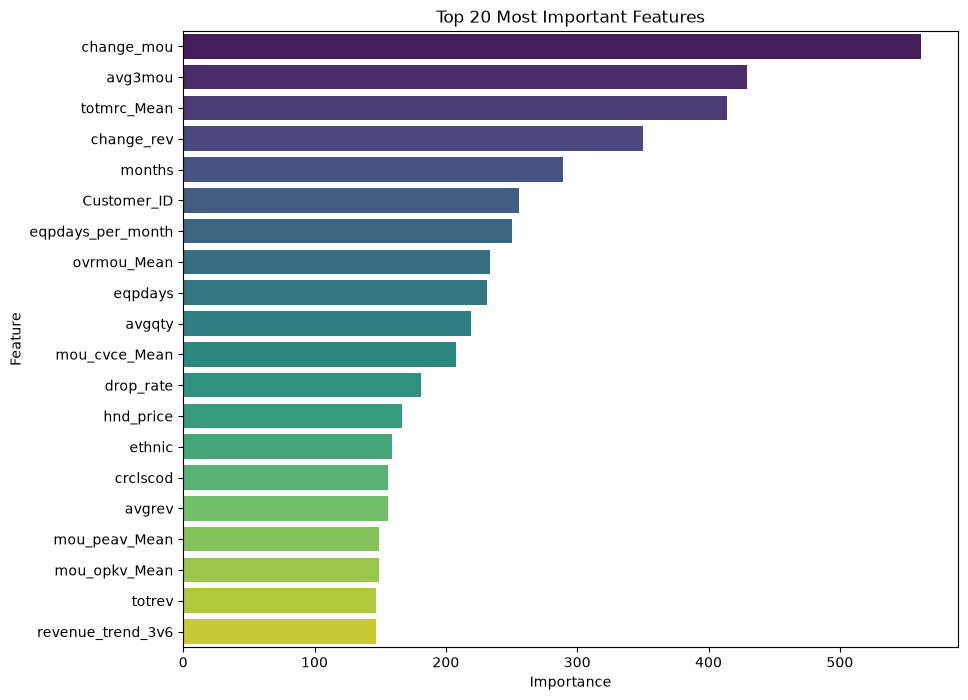

Top 10 Most Important Features:
          Feature  Importance
       change_mou         562
          avg3mou         429
      totmrc_Mean         414
       change_rev         350
           months         289
      Customer_ID         256
eqpdays_per_month         250
      ovrmou_Mean         234
          eqpdays         231
           avgqty         219


In [3]:
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. Load the prepared data
df_model = pd.read_csv('../data/processed/data_for_modeling.csv')

# 2. Separate features (X) and target (y)
X = df_model.drop(columns=['churn'])
y = df_model['churn']

# 3. Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Train a fast LightGBM model
print("Training LightGBM model...")
model = lgb.LGBMClassifier(
    n_estimators=300, 
    learning_rate=0.05, 
    random_state=42, 
    n_jobs=-1
)
model.fit(X_train, y_train)

# 5. Evaluate the model
y_pred_proba = model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"\n--- ROC-AUC Score: {auc_score:.4f} ---\n")

# 6. Extract and plot Feature Importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance.head(20), palette='viridis')
plt.title('Top 20 Most Important Features')
plt.show()

# 7. Print the top 10 features textually
print("Top 10 Most Important Features:")
print(importance.head(10).to_string(index=False))